## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [2]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


The point estimate of ATE is -0.01. I would rather not get the intra aotric balloon pump because there is a slightly higher proportion of conservative who shurvived than invasive and there is a negative ATE indicating that treatment has slightly negative impact.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [3]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

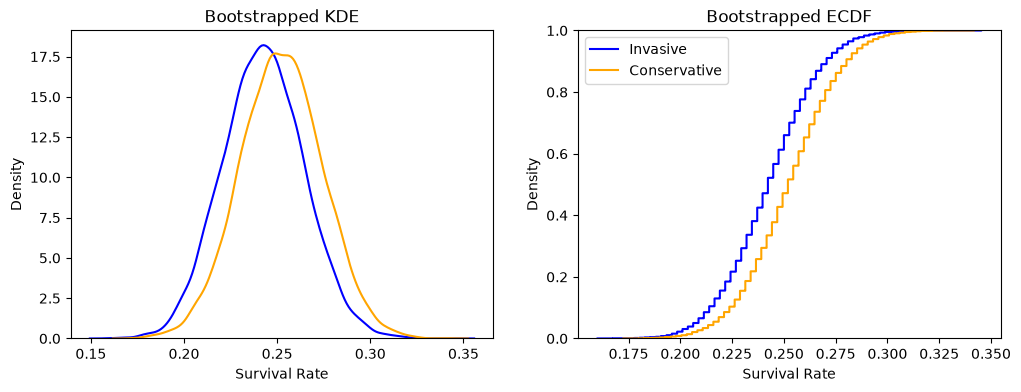

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

These plots show that conservative has a slightly higher survival rate than invasive.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

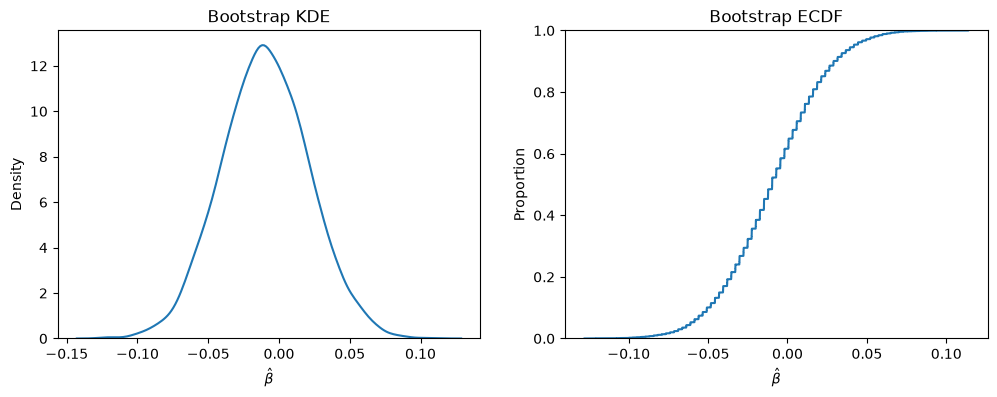

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


Bootstrap for KDE has a roughly bell shaped distribution. The range of values for this intervention are between 0 and 13.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06112024  0.04182016]
95% CI: [-0.06888533  0.05212281]
99% CI: [-0.08952946  0.07013761]


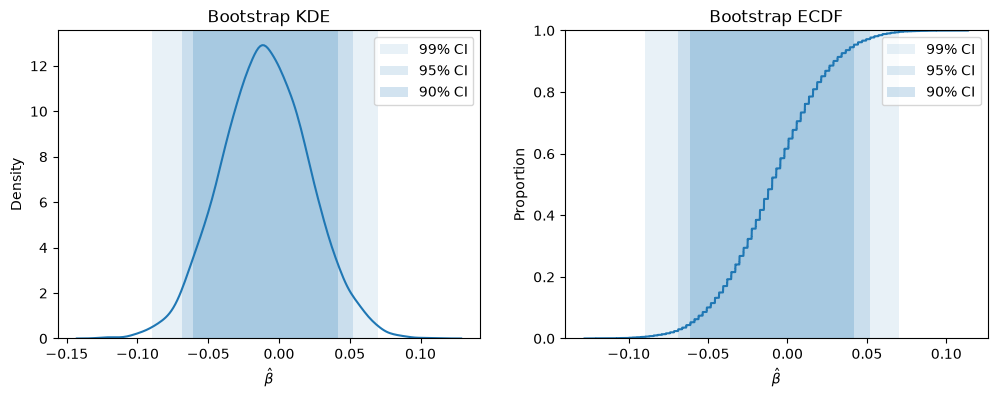

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

There is a 0 in all three confidence intervals. We would fail to reject the null hypothesis that the effect size is zero for all three as a result of zero being in all three confidence intervals.

**6.** What have we learned about inserting balloons into hearts?

Inserting balloons into hearts has a very small negative effect, but it is currently not statistically significant based on current evidence.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [37]:
#1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 

df = pd.read_csv('./data/diabetes.csv')

## met, rosi, lifestyle treatment effect:
print(pd.crosstab( df['treatment'], df['outcome']), '\n')

met_avg = df.loc[df['treatment'] == 'met', 'outcome'].eq('success').mean()
rosi_avg = df.loc[df['treatment'] == 'rosi', 'outcome'].eq('success').mean()
lifestyle_avg = df.loc[df['treatment'] == 'lifestyle', 'outcome'].eq('success').mean()
ate = df.loc[df['treatment'] == 'met', 'outcome'].eq('success').mean() \
    - df.loc[df['treatment'] == 'rosi', 'outcome'].eq('success').mean() \
    - df.loc[df['treatment'] == 'lifestyle', 'outcome'].eq('success').mean()
ate1 = df.loc[df['treatment'] == 'met', 'outcome'].eq('success').mean() \
    - df.loc[df['treatment'] == 'rosi', 'outcome'].eq('success').mean()
ate2 = df.loc[df['treatment'] == 'met', 'outcome'].eq('success').mean() \
    - df.loc[df['treatment'] == 'lifestyle', 'outcome'].eq('success').mean()
ate3 = df.loc[df['treatment'] == 'rosi', 'outcome'].eq('success').mean() \
    - df.loc[df['treatment'] == 'lifestyle', 'outcome'].eq('success').mean()

print('Average outcome for met:', np.round(met_avg, 3))
print('Average outcome for rosi:', np.round(rosi_avg, 3))
print('Average outcome for lifestyle:', np.round(lifestyle_avg, 3))
print('Estimated ATE for met vs rosi:', np.round(ate1, 3))
print('Estimated ATE for met vs lifestyle:', np.round(ate2, 3))
print('Estimated ATE for rosi vs lifestyle:', np.round(ate3, 3))


outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

Average outcome for met: 0.483
Average outcome for rosi: 0.614
Average outcome for lifestyle: 0.534
Estimated ATE for met vs rosi: -0.131
Estimated ATE for met vs lifestyle: -0.051
Estimated ATE for rosi vs lifestyle: 0.08


In [35]:
#2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 

## Bootstrapping:
R = 10_000

df_a = df.loc[ df['treatment'] == 'met',:]
df_b = df.loc[ df['treatment'] == 'rosi',:]
df_c = df.loc[ df['treatment'] == 'lifestyle',:]

outcome_a = []
outcome_b = []
outcome_c = []
ate = [] # Store computed effects
ate2 = [] # Store computed effects
ate3 = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)
    df_ct = df_c.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['outcome'].eq('success').mean() # Mean outcome for A
    obt = df_bt['outcome'].eq('success').mean() # Mean outcome for B    
    oct = df_ct['outcome'].eq('success').mean() # Mean outcome for C

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample for met vs rosi
    ate_t2 = oat - oct # Compute ATE for this bootstrap sample for met vs lifestyle
    ate_t3 = obt - oct # Compute ATE for this bootstrap sample for rosi vs lifestyle
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    outcome_c.append(oct) # Save new value
    ate.append(ate_t) # Save new value
    ate2.append(ate_t2) # Save new value
    ate3.append(ate_t3) # Save new value

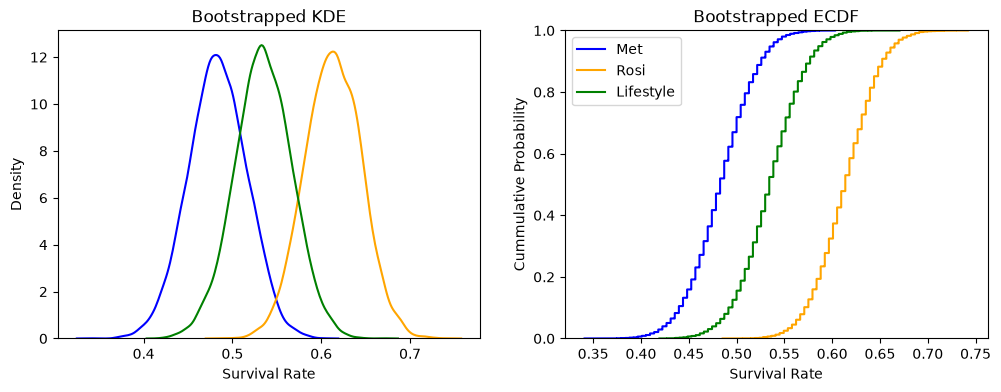

In [25]:
#3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Met', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Rosi', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')
sns.kdeplot(outcome_c, label='Lifestyle', color='green', ax=ax[0])

sns.ecdfplot(outcome_a, label='Met', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Rosi', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Cummulative Probability')
sns.ecdfplot(outcome_c, label='Lifestyle', color='green', ax=ax[1])

plt.legend()
plt.show()

Rosi appears to have the highest survival rate of the three while met has the lowest survival rate of the three.

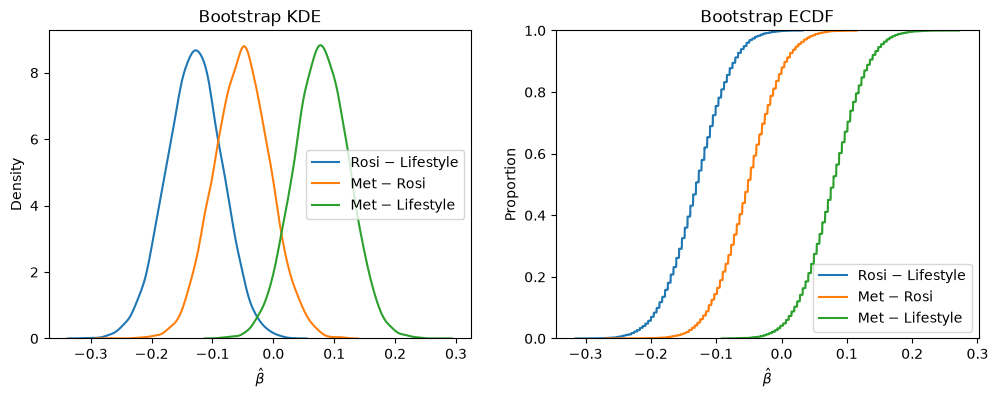

In [30]:
#4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, label='Rosi − Lifestyle',ax=ax[0])
sns.kdeplot(ate2, label='Met − Rosi', ax=ax[0])
sns.kdeplot(ate3, label='Met − Lifestyle', ax=ax[0]) 
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, label='Rosi − Lifestyle',ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
sns.ecdfplot(ate2, label='Met − Rosi', ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
sns.ecdfplot(ate3, label='Met − Lifestyle', ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()
plt.show()


In [31]:

#5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?
ci90 = np.quantile(ate, [.05, .95])
ci90_1 = np.quantile(ate2, [.05, .95])
ci90_2 = np.quantile(ate3, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci95_1 = np.quantile(ate2, [.025, .975])
ci95_2 = np.quantile(ate3, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])
ci99_1 = np.quantile(ate2, [.005, .995])
ci99_2 = np.quantile(ate3, [.005, .995])

print(f"90% CI (Rosi − Lifestyle): {ci90}")
print(f"90% CI (Met vs Rosi): {ci90_1}")
print(f"90% CI (Met vs Lifestyle): {ci90_2}")

print(f"95% CI (Rosi − Lifestyle): {ci95}")
print(f"95% CI (Met vs Rosi): {ci95_1}")
print(f"95% CI (Met vs Lifestyle): {ci95_2}")

print(f"99% CI (Rosi − Lifestyle): {ci99}")
print(f"99% CI (Met vs Rosi): {ci99_1}")
print(f"99% CI (Met vs Lifestyle): {ci99_2}")


90% CI (Rosi − Lifestyle): [-0.20419657 -0.05373964]
90% CI (Met vs Rosi): [-0.12846301  0.02567787]
90% CI (Met vs Lifestyle): [0.0066386  0.15232383]
95% CI (Rosi − Lifestyle): [-0.22130753 -0.04071657]
95% CI (Met vs Rosi): [-0.14146773  0.03890363]
95% CI (Met vs Lifestyle): [-0.01034445  0.16523605]
99% CI (Rosi − Lifestyle): [-0.25135045 -0.01481787]
99% CI (Met vs Rosi): [-0.17160349  0.06863432]
99% CI (Met vs Lifestyle): [-0.03611395  0.19513242]


Among the intervals, there is no zero in the intervals for Rosi vs Lifestyle for 90% confidence interval and Rosi vs Lifestyle for 90%, 95%, and 99% confidence intervals, indicating there is statistical significance differences for these comparisons. Rosi appears to be the most effective based on a higher observed success rate at 0.614 compared to lifestyle at 0.534 and met at 0.483.

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

Three interventions for diabetes were compared, being met, rosi, and lifestyle. The observed success rate was highest for rosi at 0.614, then lifestyle at 0.534, and finally met at 0.483. This indicates that rosi has the best success rate of the three.

Bootstrap comparisons were used to resample participants within each treatment arm. All three confidence intervals of 90%, 95%, and 99% in rosi vs lifestyle did not include zero when rosi compared to lifestyle, supporting the previous evidence indicating rosi had the highest success rate. The confidence interval for met vs lifestyle at 90% excluding zero but including zero at 95% and 99% indicates it is a less statistically significant comparison compared to rosi vs lifestyle. Zero was included in all confidence intervals for met vs rosi, indicating it is not a statistically significant result.

From the evidence, rosi is the best candidate for adoption, especially compared to lifestyle. However, this does not take into account potential costs, side effects, or other unknown clinical outcomes at this time. The evidence also does not immediately determine whether to adopt or reject met compared to the other two, especially for met vs lifestyle comparison.